# PydanticAI together with Pydantic Models

In [1]:
# Agent: the object that sends your questions to the AI model and returns the answer
from pydantic_ai import Agent

# OpenAIChatModel: a wrapper that talks to any service using OpenAI's chat format
from pydantic_ai.models.openai import OpenAIChatModel

# OpenAIProvider: holds the connection details (where to connect and how to log in)
from pydantic_ai.providers.openai import OpenAIProvider

import os  # lets us read environment variables

from dotenv import load_dotenv  # reads key=value pairs from a .env file

# Load the variables from your .env file (e.g. NVIDIA_API=...) into the environment.
# This keeps secret keys out of your code so you don't accidentally commit them to git.
load_dotenv()

# Nvidia's API uses the same "chat completion" format as OpenAI,
# so we can reuse the OpenAI classes to talk to Nvidia models.
model = OpenAIChatModel(
    "nvidia/nemotron-3.5-lightning-30b-a3b",
    provider=OpenAIProvider(
        base_url="https://integrate.api.nvidia.com/v1",
        api_key=os.environ["NVIDIA_API"],
    ),
)


In [2]:
employee_simulator = Agent(
    model=model,
    instructions="""Du är expert på att simulera anställda i Sverige.
    Följ detta format:
    name: "Bertil"
    age: 40
    salary: 35000
    role: "IT-supporter"
    ort: "Göteborg"
    """,
)

result = await employee_simulator.run(
    "Ge mig en data engineer som jobbar i Stockholm"
)
print(result.output)

employee_simulator = Agent(
    model=model,
    instructions="""Du är expert på att simulera anställda i Sverige.
    Följ detta format:
    name: "Bertil"
    age: 40
    salary: 35000
    role: "IT-supporter"
    ort: "Göteborg"
    """,
)

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm ")
print(result.output)

                 pydantic-ai v2.62.0 • Python 3.13.7

      / \        agent: employee_simulator • model: openai:nvidia/nemotron-3.5-lightning-30b-a3b
     /   \         tools: 0 • capabilities: 0
   /___.___\
  /    |    \    observability: off — see every model and tool call live, with cost
/      |      \    set it up free with Pydantic Logfire: uvx logfire-cli wizard --task pydantic-ai
`---.._|_..---'    or use any OpenTelemetry backend: https://pydantic.dev/docs/ai/logfire/#otel

                 goes away once observability is on — or PYDANTIC_AI_NO_BANNER=1


name: "Johan"
age: 35
salary: 45000
role: "Data Engineer"
ort: "Stockholm"
name: "Miriam"
age: 32
salary: 52000
role: "Data engineer"
ort: "Stockholm"


## Force a structured output using pydantic

In [3]:
from pydantic import BaseModel, Field


class EmployeeModel(BaseModel):
    name: str = Field(
        description="för och efternamn, inte jättelångt, svenska eller internationella namn"
    )
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(
        description="lön mellan 30k-60k, ju mer senior position, desto högre lön",
        ge=30_000,
        lt=60_000,
    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(
    name="Bertil",
    age=40,
    salary=30000,
    role="IT supporter",
    description="Hjälper folk med IT",
)

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT supporter', description='Hjälper folk med IT')

In [4]:
employee_simulator = Agent(
    model=model,
    instructions="Du är expert på att simulera anställda i Sverige",
)

result = await employee_simulator.run("Ge mig en data engineer i stockholm")

result.output

'Jag kan inte ge dig en specifik persons kontaktuppgifter eller privata data, men jag kan hjälpa dig med en realistisk profil av en data engineer i Stockholm, samt var och hur du hittar dem beroende på vad du behöver.\n\n### Typisk data engineer i Stockholm (profil)\n- **Teknikstack:** Python, SQL, Apache Airflow/Docker, molntjänster (AWS, GCP eller Azure), erfarenhet av datawarehouses som Snowflake, Redshift eller BigQuery, ofta också Kafka eller dbt.\n- **Utbildning:** Vanligtvis akademisk bakgrund inom datavetenskap, teknik eller naturvetenskap (existerar många med master från KTH, Stockholm University eller Chalmers).\n- **Erfarenhet:** 2–5 år i rollen för junior, 5+ för senior. Många jobbar inom fintech, e-handel, offentlig sector eller SaaS.\n- **Lön:** Enligt SCB och branschråden ligger snittlönen runt 45 000–65 000 kr/mån (frånvaro av bonus/aktier), seniora kan tjäna högre, särskilt i aktiebaserade bolag.\n- **Var hittar man dem:** LinkedIn (starkt i Stockholm), Ovik, Blueskip,

In [5]:
result = await employee_simulator.run(
    "Ge mig en data engineer i stockholm", output_type=EmployeeModel
)
result

AgentRunResult(output=EmployeeModel(name='Johan Karlsson', age=32, salary=45000, role='Data Engineer', description='Designs and maintains data pipelines and warehouses in Stockholm. Works with cloud platforms and ensures data quality.'))

In [6]:
employee2 = result.output
employee2

EmployeeModel(name='Johan Karlsson', age=32, salary=45000, role='Data Engineer', description='Designs and maintains data pipelines and warehouses in Stockholm. Works with cloud platforms and ensures data quality.')

In [7]:
type(employee2)

__main__.EmployeeModel

In [8]:
employee2.name + " är cool"

'Johan Karlsson är cool'

In [9]:
employee2.salary

45000

In [10]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [11]:
employee2.__dict__.values()

dict_values(['Johan Karlsson', 32, 45000, 'Data Engineer', 'Designs and maintains data pipelines and warehouses in Stockholm. Works with cloud platforms and ensures data quality.'])

In [12]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Johan Karlsson
age: 32
salary: 45000
role: Data Engineer
description: Designs and maintains data pipelines and warehouses in Stockholm. Works with cloud platforms and ensures data quality.


## Simulate many employees

In [13]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])
result

AgentRunResult(output=[EmployeeModel(name='Alice Ericsson', age=30, salary=45000, role='Software Developer', description='Develops backend services for enterprise applications. Works closely with cross‑functional teams to improve system performance.'), EmployeeModel(name='Liam Nilsson', age=35, salary=52000, role='DevOps Engineer', description='Manages CI/CD pipelines and cloud infrastructure. Ensures reliable deployment and scaling of services.'), EmployeeModel(name='Sofia Andersson', age=28, salary=38000, role='HR Specialist', description='Handles recruitment onboarding and employee relations. Supports performance management processes.'), EmployeeModel(name='Marcus Karlsson', age=45, salary=55000, role='HR Manager', description='Oversees talent acquisition strategy and develops corporate culture initiatives. Manages HR policy compliance.'), EmployeeModel(name='Emma Nilsson', age=27, salary=40000, role='Marketing Coordinator', description='Coordinates digital marketing campaigns and s

## Task - calculate mean salary 

In [14]:
employees = result.output

employees

[EmployeeModel(name='Alice Ericsson', age=30, salary=45000, role='Software Developer', description='Develops backend services for enterprise applications. Works closely with cross‑functional teams to improve system performance.'),
 EmployeeModel(name='Liam Nilsson', age=35, salary=52000, role='DevOps Engineer', description='Manages CI/CD pipelines and cloud infrastructure. Ensures reliable deployment and scaling of services.'),
 EmployeeModel(name='Sofia Andersson', age=28, salary=38000, role='HR Specialist', description='Handles recruitment onboarding and employee relations. Supports performance management processes.'),
 EmployeeModel(name='Marcus Karlsson', age=45, salary=55000, role='HR Manager', description='Oversees talent acquisition strategy and develops corporate culture initiatives. Manages HR policy compliance.'),
 EmployeeModel(name='Emma Nilsson', age=27, salary=40000, role='Marketing Coordinator', description='Coordinates digital marketing campaigns and social media conten

In [15]:
salary = 0

for employee in employees:
    salary += employee.salary

salary/len(employees)

47600.0

## Convert to dataframe

In [16]:
employees[0].model_dump()

{'name': 'Alice Ericsson',
 'age': 30,
 'salary': 45000,
 'role': 'Software Developer',
 'description': 'Develops backend services for enterprise applications. Works closely with cross‑functional teams to improve system performance.'}

In [17]:
import pandas as pd
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Alice Ericsson,30,45000,Software Developer,Develops backend services for enterprise appli...
1,Liam Nilsson,35,52000,DevOps Engineer,Manages CI/CD pipelines and cloud infrastructu...
2,Sofia Andersson,28,38000,HR Specialist,Handles recruitment onboarding and employee re...
3,Marcus Karlsson,45,55000,HR Manager,Oversees talent acquisition strategy and devel...
4,Emma Nilsson,27,40000,Marketing Coordinator,Coordinates digital marketing campaigns and so...


In [18]:
# df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

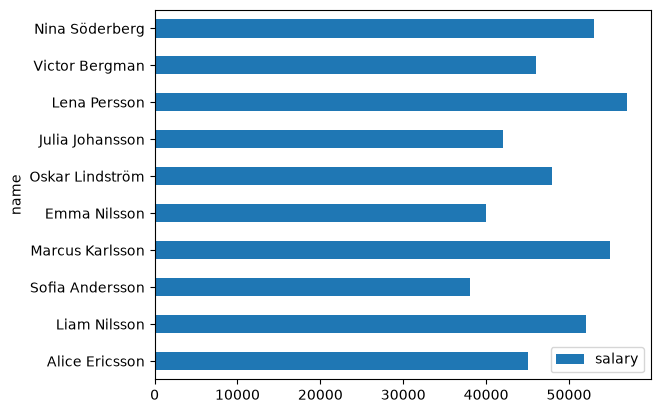

In [19]:
df.plot(kind = "barh", x = "name", y = "salary")